In [85]:
# Lab_EDA_Uni_Analysis

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
# cargando el df
#df = pd.read_csv(r"C:\Users\juanc\OneDrive\Desktop\date analytics 2026\lab-eda-univariate\amz_uk_price_prediction_dataset.csv")
# mal

In [ ]:
df.head()


,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [89]:
# frecuencia
category_freq = df["category"].value_counts()
category_freq


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Motorbike Chassis                            107
Alexa Built-In Devices                       107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [90]:
# top 5
top_5_categories = category_freq.head(5)
top_5_categories


category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

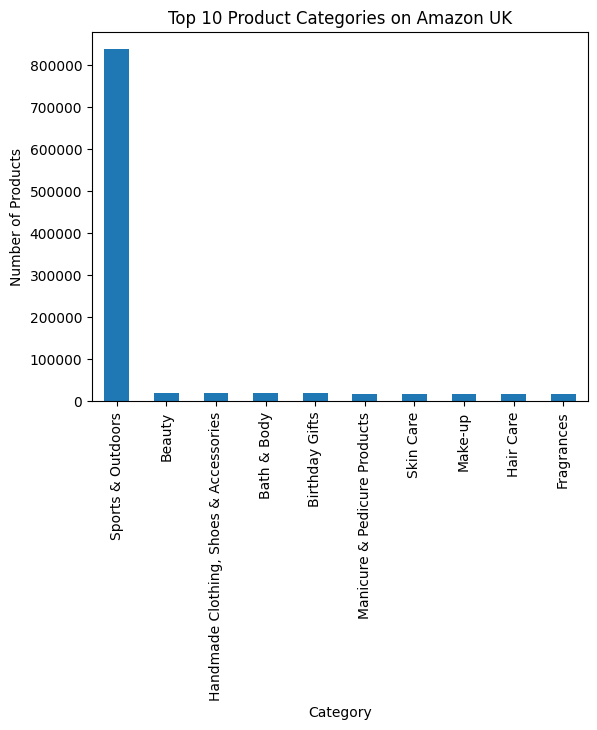

In [91]:
# Barchart distribucion por categorias
top_10_categories = category_freq.head(10)
top_10_categories.plot(kind="bar")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.title("Top 10 Product Categories on Amazon UK")
plt.show()


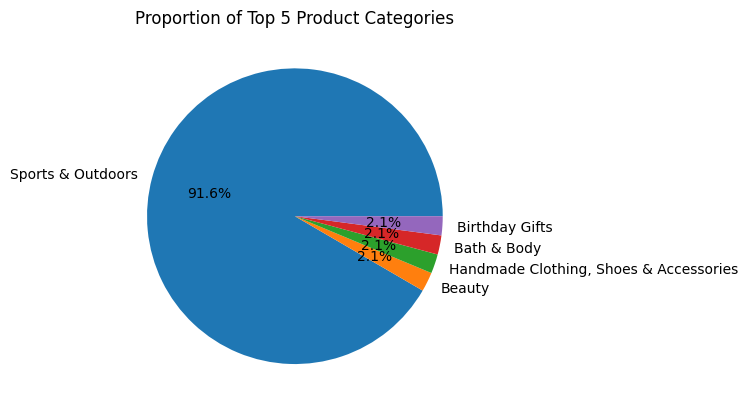

In [92]:
top_5_categories.plot(kind="pie", autopct="%1.1f%%")
plt.ylabel("")
plt.title("Proportion of Top 5 Product Categories")
plt.show()


In [93]:
# tendencia
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

mean_price


np.float64(89.24380943923661)

In [94]:
median_price

np.float64(19.09)

In [95]:
mode_price

np.float64(9.99)

In [96]:
# variancia - desviacion - rango - rango IQR
#  
price_variance = df["price"].var()
price_std = df["price"].std()
price_range = df["price"].max() - df["price"].min()

q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
price_iqr = q3 - q1

price_variance, price_std, price_range, price_iqr


(np.float64(119445.48532254901),
 np.float64(345.60886175349873),
 np.float64(100000.0),
 np.float64(36.0))

In [97]:
import matplotlib.pyplot as plt

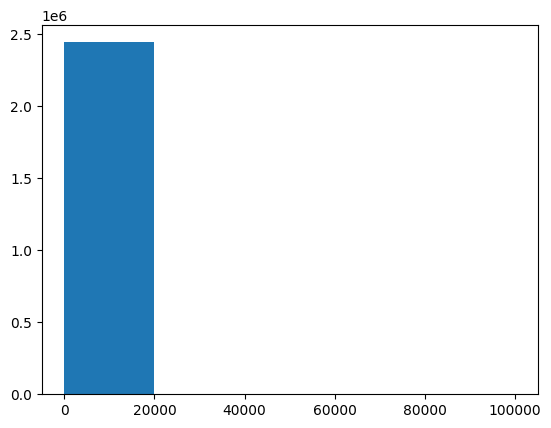

In [98]:
# histograma

plt.hist(df["price"], bins=5);

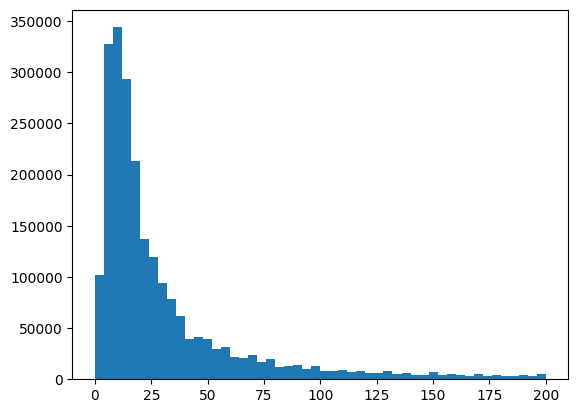

In [99]:
plt.hist(df[df["price"] < 200]["price"], bins=50);


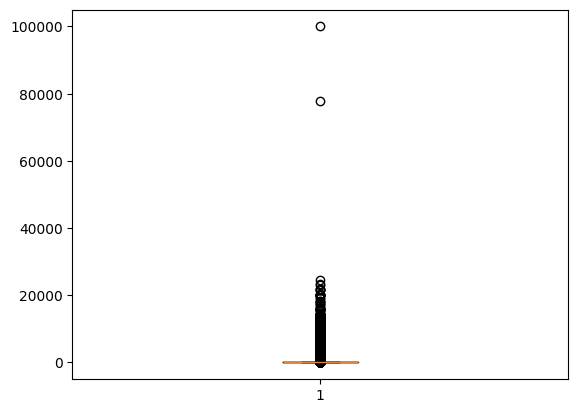

In [100]:
plt.boxplot(df["price"]);


### Measures of Centrality (stars)

In [101]:
df["stars"].mean()


np.float64(2.152836472966066)

In [102]:
df["stars"].median()


np.float64(0.0)

In [103]:
df["stars"].mode()[0]


np.float64(0.0)

### dispercion

In [104]:
df["stars"].var()

np.float64(4.817434029796864)

In [105]:
df["stars"].std()


np.float64(2.194865378513421)

In [106]:
df["stars"].quantile(0.75) - df["stars"].quantile(0.25)


np.float64(4.4)

### distribucion

In [107]:
df["stars"].skew() # asimetria


np.float64(0.08120735761080881)

In [108]:
df["stars"].kurt() # apuntamineto


np.float64(-1.9260061280432994)

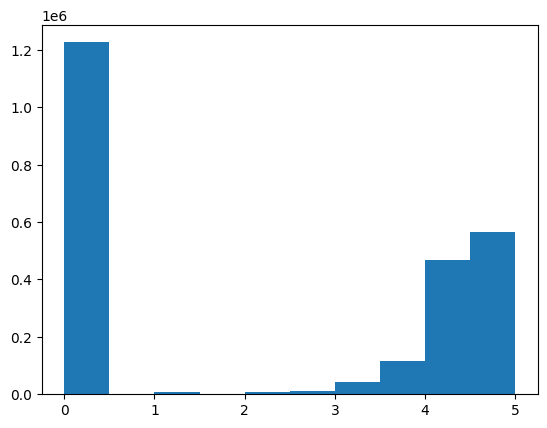

In [109]:
# histograma Stars
plt.hist(df["stars"], bins=10);


### principales hallazgos:
- el dataset tiene 296 diferentes categorias, donde sport y outdoor superan por una amplia diferencia al resto, con mas de 800.000 productos, las siguientes ya estan todas sobre los 19.000 productos.

### Negocio
La fuerte dominancia de Sports & Outdoors sugiere un mercado altamente competitivo y saturado, mientras que las categorías con menor volumen pueden representar oportunidades de nicho con menor nivel de competencia.

### Precio de los productos
Medidas de Tendencia Central
- Precio medio: £89,24
- Precio mediano: £19,09
- Frecuente (moda): £9,99
- La gran diferencia entre la media y la mediana indica una distribución fuertemente sesgada a la derecha, causada por un pequeño número de productos con precios muy elevados.

### Medidas de Dispersión
- Desviación estándar: £345,61
- Rango de precios: £100.000
- Rango intercuartílico (IQR): £36
La mayoria de los productos se centran en precios bajos, salvo unos pocos q son extremadamente caros, generando una dispersion de los datos

### visual
En el analisis visual, podemos ver q en su mayoria son productos de precios bajos por mas q tengamos productos con alta dispercion de precios!
El diagrama de caja confirma la existencia de numerosos valores atípicos en la parte superior de la distribución.

El marketplace de Amazon UK, esta dominado por productos de bajo precio, los productos premium constituyen un segmento reducido pero con fuerte impacto en las métricas agregadas




### valoracion

Medidas de Tendencia Central
- Valoración media: 2,15
- Valoración mediana: 0
- Valoración más frecuente (moda): 0

Esto indica que más de la mitad de los productos no cuenta con valoraciones de clientes, lo que suele estar asociado a productos nuevos o con bajo volumen de ventas

### Análisis Visual
- El histograma muestra un pico muy pronunciado en 0 estrellas.
- Las valoraciones entre 1 y 5 estrellas aparecen en menor proporción, confirmando la escasez de feedback para la mayoría de los productos

La falta de valoraciones en la mayoría de los productos resalta la importancia de estrategias orientadas a generar reseñas

### Conclusión

El análisis revela una fuerte concentración por categorías, una distribución de precios altamente asimétrica dominada por productos económicos y una gran proporción de productos sin valoraciones. Estos resultados sugieren que, para competir eficazmente en Amazon UK, no solo es clave una estrategia de precios adecuada, sino también una correcta selección de categorías y acciones activas para incentivar la obtención de valoraciones de clientes